# 🎯 Internship Placement Readiness Predictor — Training Notebook

**Goal:** predict whether a student's profile is *Placement Ready* (`Placed`) or `Needs Upskilling`, output a readiness score such as **"84% — Placement Ready"**, and support "what-if" feedback in the Streamlit app.

**Pipeline:** load → clean → EDA → feature engineering → train 3 models (Logistic Regression, Random Forest, Gradient Boosting) → evaluate → select best → save `model.joblib`.

> **Dataset note.** Place the Kaggle *Campus Recruitment & Employability Factors* CSV at `training/data/campus_recruitment.csv`.
> If the file is absent, the notebook generates a **synthetic stand-in dataset (2,100 rows)** with the same schema so the whole project runs end-to-end.
> The data source is stored inside `model.joblib` and shown in the app, so a synthetic model can never be mistaken for a real one.

## 1. Setup & configuration

In [1]:
import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

RANDOM_STATE = 42
DATA_PATH = Path("data/campus_recruitment.csv")   # put the Kaggle CSV here
MODEL_PATH = Path("../model.joblib")              # saved next to app.py
THRESHOLD = 0.50                                  # P(Placed) >= 0.50  ->  "Placement Ready"

# ---- Exact feature order (the Streamlit app must use this same order) ----
FEATURES    = ["cgpa", "aptitude_score", "soft_skills", "projects", "internship", "specialization"]
NUMERIC     = ["cgpa", "aptitude_score", "soft_skills", "projects"]
BINARY      = ["internship"]
CATEGORICAL = ["specialization"]
TARGET      = "placed"   # 1 = Placed, 0 = Needs Upskilling
print("Feature order:", FEATURES)

Feature order: ['cgpa', 'aptitude_score', 'soft_skills', 'projects', 'internship', 'specialization']


## 2. Load data
`make_synthetic` is only a **fallback** so the repo is runnable without a Kaggle login. For the real project, download the Kaggle CSV and drop it into `training/data/`.

In [2]:
def make_synthetic(n=2100, seed=RANDOM_STATE):
    # Synthetic stand-in with Kaggle-style column names (used only if the real CSV is missing).
    rng = np.random.default_rng(seed)
    specs = ["Computer Science", "Information Technology", "Data Science",
             "Electronics & Communication", "Mechanical Engineering", "Business Analytics"]
    bonus = dict(zip(specs, [0.5, 0.4, 0.6, 0.0, -0.5, 0.1]))
    spec   = rng.choice(specs, n, p=[.25, .20, .12, .18, .15, .10])
    cgpa   = np.clip(rng.normal(7.4, 0.9, n), 4.5, 10).round(2)
    apt    = np.clip(rng.normal(62, 15, n) + (cgpa - 7.4) * 5, 0, 100).round(1)
    soft   = np.clip(rng.normal(6.2, 1.5, n), 1, 10).round(1)
    proj   = np.clip(rng.poisson(2.2, n), 0, 10)
    intern = rng.binomial(1, 0.45, n)
    z = (-9.2 + 0.55 * cgpa + 0.035 * apt + 0.30 * soft + 0.35 * proj + 0.9 * intern
         + np.array([bonus[s] for s in spec]) + rng.normal(0, 0.9, n))
    placed = rng.random(n) < 1 / (1 + np.exp(-z))
    df = pd.DataFrame({
        "CGPA": cgpa, "Aptitude Test Score": apt, "Soft Skills Rating": soft,
        "Projects Completed": proj, "Internship Experience": np.where(intern == 1, "Yes", "No"),
        "Specialization": spec,
        "Placement Status": np.where(placed, "Placed", "Needs Upskilling"),
    })
    # inject a little missingness so the cleaning/imputation steps are exercised
    for col in ["Aptitude Test Score", "Soft Skills Rating"]:
        df.loc[rng.choice(n, int(n * 0.015), replace=False), col] = np.nan
    return df

if DATA_PATH.exists():
    raw, DATA_SOURCE = pd.read_csv(DATA_PATH), "kaggle"
else:
    raw, DATA_SOURCE = make_synthetic(), "synthetic"
print(f"Data source: {DATA_SOURCE} | shape: {raw.shape}")
raw.head()

Data source: synthetic | shape: (2100, 7)


,CGPA,Aptitude Test Score,Soft Skills Rating,Projects Completed,Internship Experience,Specialization,Placement Status
0,7.73,53.4,6.5,2,No,Mechanical Engineering,Placed
1,7.92,56.2,7.6,2,No,Information Technology,Needs Upskilling
2,6.96,65.2,4.5,3,No,Mechanical Engineering,Needs Upskilling
3,5.77,73.9,6.2,5,Yes,Electronics & Communication,Placed
4,6.86,75.1,4.5,2,No,Computer Science,Placed


## 3. Cleaning
Raw columns are mapped to standard names through an alias table (so slightly different Kaggle column headers still work), the target is encoded, and invalid rows are removed.

In [3]:
def norm(c):  # "Aptitude Test Score" -> "aptitude_test_score"
    return re.sub(r"[^a-z0-9]+", "_", str(c).lower()).strip("_")

ALIASES = {
    "cgpa":            ["cgpa", "academic_percentage", "academic_score", "percentage", "gpa"],
    "aptitude_score":  ["aptitude_test_score", "technical_test_score", "aptitude_score", "technical_score", "test_score"],
    "soft_skills":     ["soft_skills_rating", "soft_skills", "communication_skills", "communication_rating"],
    "projects":        ["projects_completed", "number_of_projects", "projects", "hands_on_projects"],
    "internship":      ["internship_experience", "internships", "internship"],
    "specialization":  ["specialization", "degree_specialization", "branch", "degree"],
    "placement_status":["placement_status", "placement", "placed", "status"],
}

def standardise(df):
    cols = {norm(c): c for c in df.columns}
    rename = {}
    for std, options in ALIASES.items():
        hit = next((cols[o] for o in options if o in cols), None)
        if hit is None:
            raise KeyError(f"Could not find a column for '{std}'. Tried {options}. Found {list(df.columns)}. "
                           "Edit ALIASES in this cell to match your CSV.")
        rename[hit] = std
    return df.rename(columns=rename)[list(ALIASES)]

df = standardise(raw)

# --- target: Placed -> 1, Needs Upskilling / Not Placed -> 0
status = df.pop("placement_status").astype(str).str.strip().str.lower()
POS, NEG = {"placed", "yes", "1", "placement ready"}, {"needs upskilling", "not placed", "no", "0"}
unknown = set(status) - POS - NEG
assert not unknown, f"Unmapped target labels: {unknown}"
df[TARGET] = status.isin(POS).astype(int)

# --- internship: Yes/No -> 1/0
df["internship"] = (df["internship"].astype(str).str.strip().str.lower()
                    .map({"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0}))

# --- types, duplicates, invalid values
for c in NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df.loc[df[c] < 0, c] = np.nan
df["specialization"] = df["specialization"].astype(str).str.strip().replace({"nan": np.nan})

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate rows. Final shape: {df.shape}")
print("\nMissing values per column:"); print(df.isna().sum())

Dropped 0 duplicate rows. Final shape: (2100, 7)

Missing values per column:
cgpa               0
aptitude_score    31
soft_skills       31
projects           0
internship         0
specialization     0
placed             0
dtype: int64


## 4. Exploratory data analysis

                 count   mean    std   min   25%    50%    75%    max
cgpa            2100.0   7.41   0.89  4.64   6.8   7.41   8.01   10.0
aptitude_score  2069.0  62.19  15.93  0.00  52.1  62.60  72.80  100.0
soft_skills     2069.0   6.19   1.48  1.60   5.2   6.10   7.20   10.0
projects        2100.0   2.21   1.48  0.00   1.0   2.00   3.00    9.0


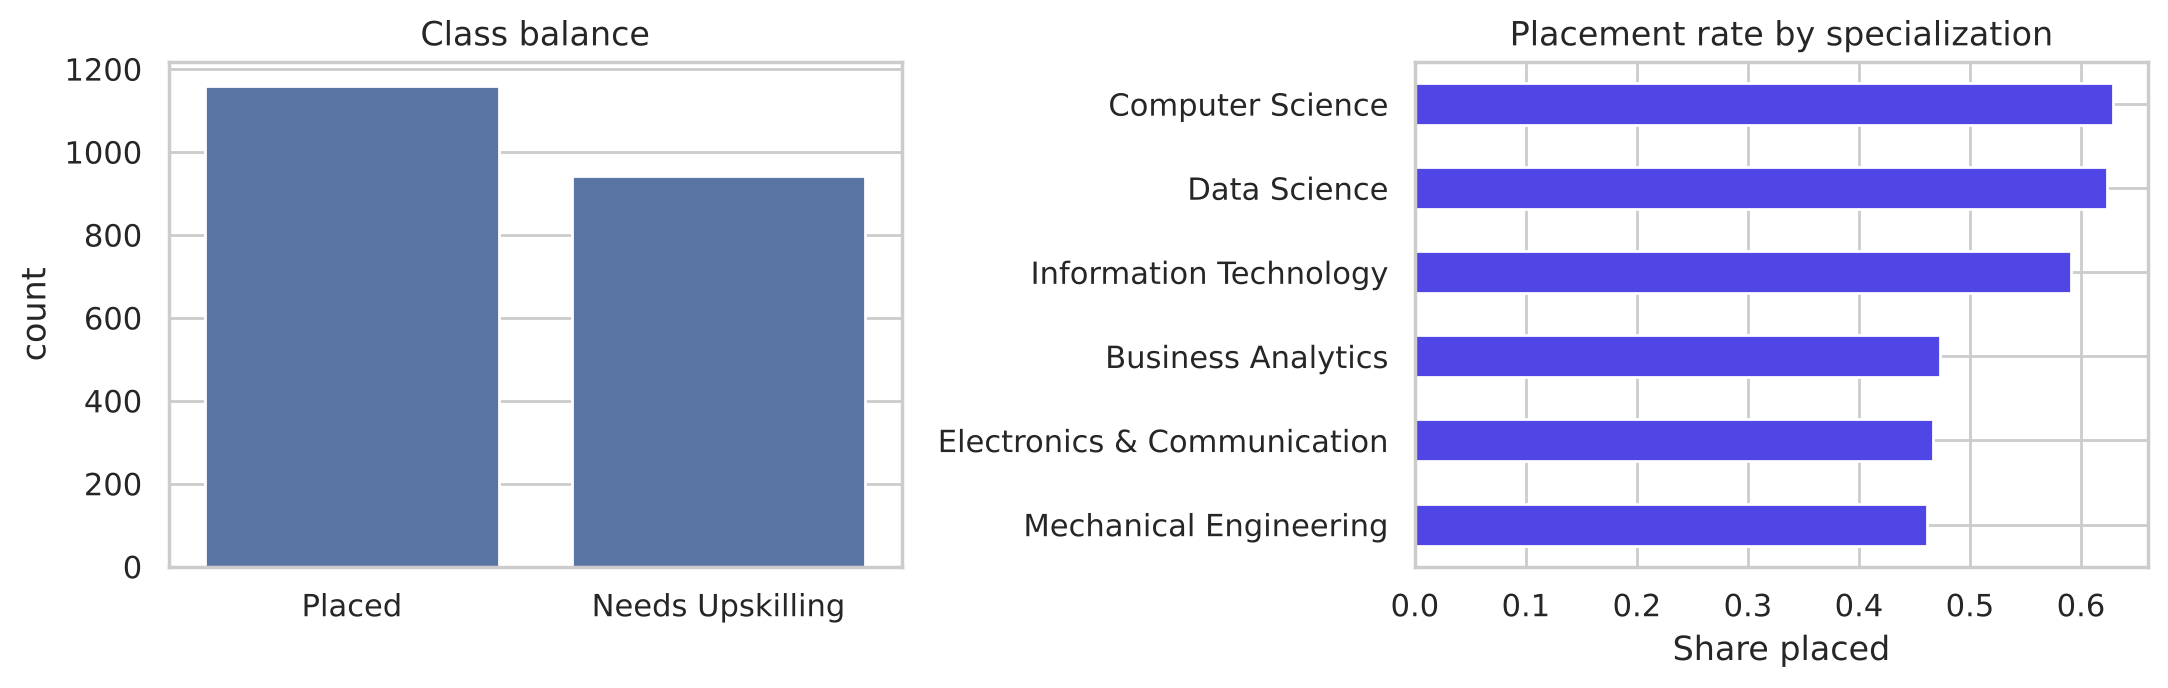

Placed share: 55.2%


In [4]:
print(df[NUMERIC].describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(x=df[TARGET].map({1: "Placed", 0: "Needs Upskilling"}), ax=axes[0])
axes[0].set_title("Class balance"); axes[0].set_xlabel("")
rate = df.groupby("specialization")[TARGET].mean().sort_values()
rate.plot.barh(ax=axes[1], color="#4f46e5"); axes[1].set_title("Placement rate by specialization")
axes[1].set_xlabel("Share placed"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Placed share: {df[TARGET].mean():.1%}")

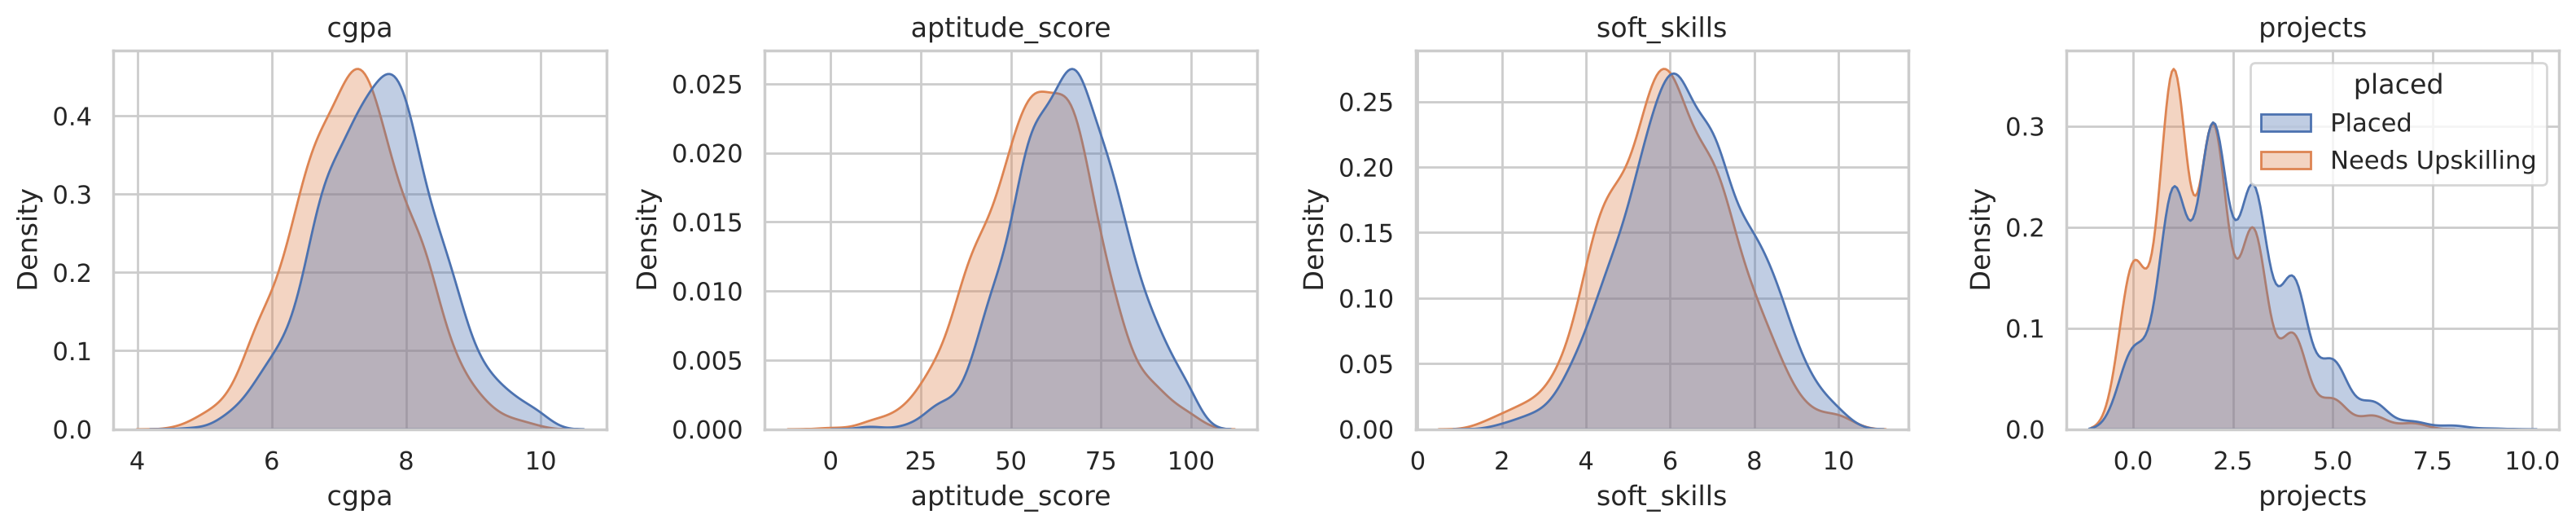

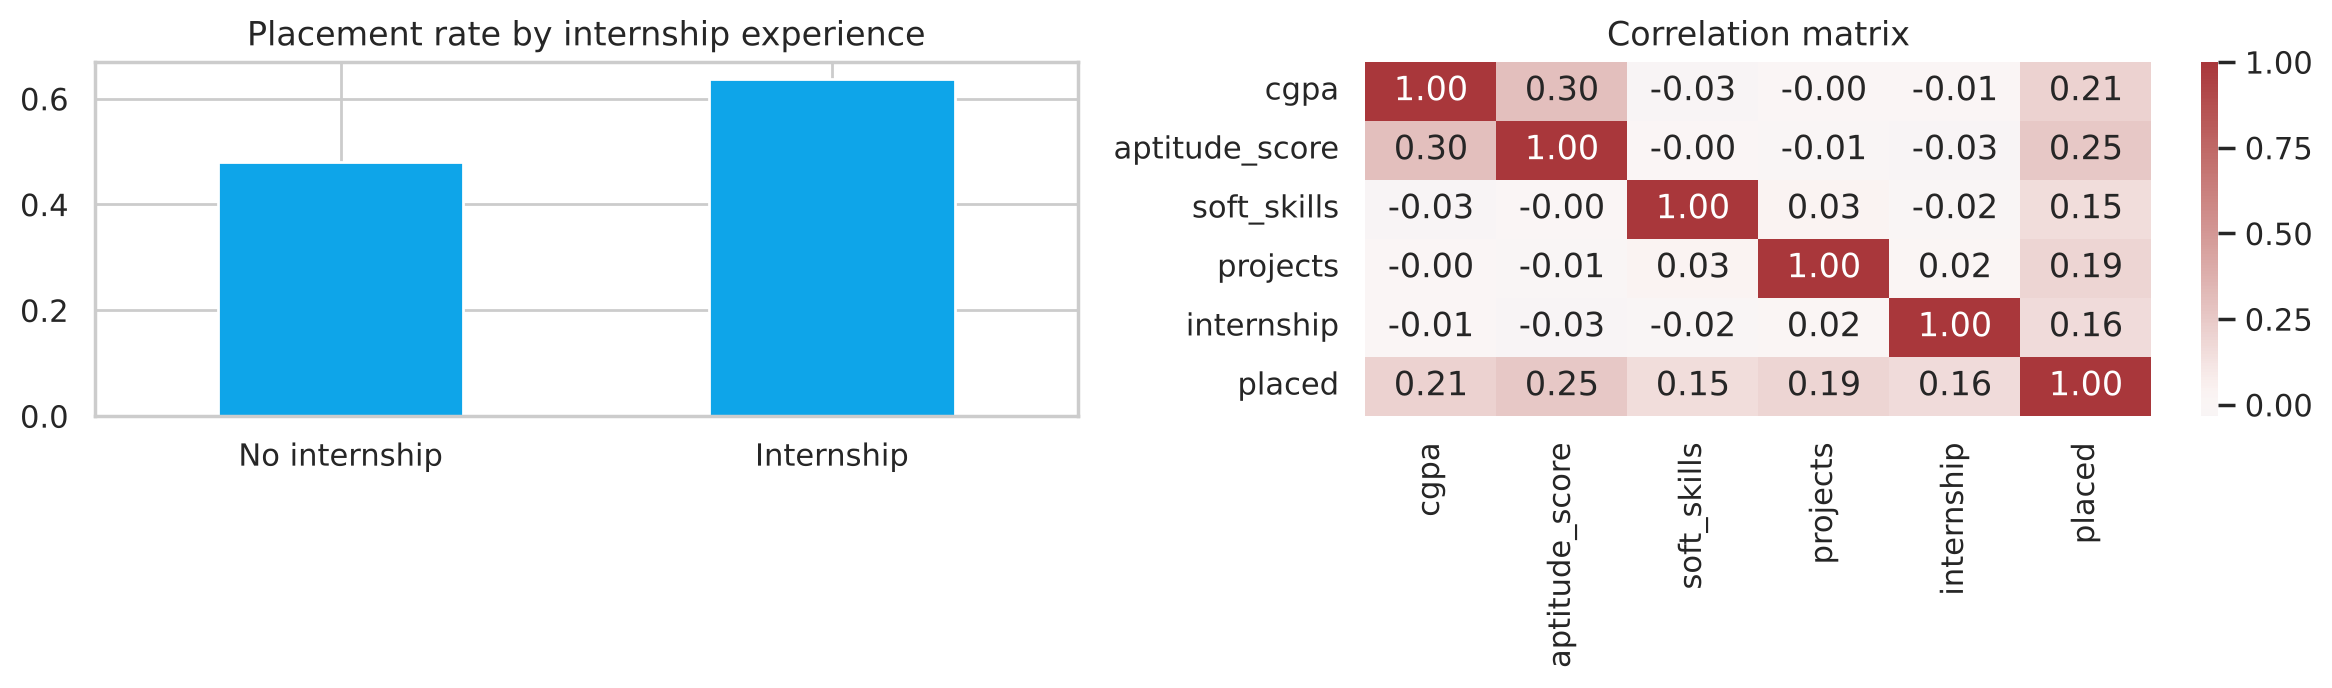

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, NUMERIC):
    sns.kdeplot(data=df, x=col, hue=df[TARGET].map({1: "Placed", 0: "Needs Upskilling"}),
                common_norm=False, fill=True, alpha=.35, ax=ax, legend=(col == NUMERIC[-1]))
    ax.set_title(col)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
df.groupby("internship")[TARGET].mean().rename({0: "No internship", 1: "Internship"}).plot.bar(ax=axes[0], color="#0ea5e9", rot=0)
axes[0].set_title("Placement rate by internship experience"); axes[0].set_xlabel("")
sns.heatmap(df[NUMERIC + BINARY + [TARGET]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 5. Feature engineering
The six raw features map **1-to-1 to the Streamlit input widgets**, so the app can never feed the model something it was not trained on.
Derived features (e.g. `cgpa x projects`) add little for tree models and make the "what-if" feedback harder to explain, so they are intentionally **not** used.
Preprocessing lives inside the sklearn `Pipeline` (median imputation + scaling for numeric, one-hot for specialization), which prevents train/test leakage and ships with the model.

In [6]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

def make_preprocessor(scale=True):
    num = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num), NUMERIC),
        ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
    ])

(1680, 6) (420, 6)


## 6. Train & tune the three models
5-fold stratified `GridSearchCV` optimising ROC-AUC (small grids to keep runtime short).

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": (
        Pipeline([("prep", make_preprocessor(scale=True)),
                  ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1, 10]}),
    "Random Forest": (
        Pipeline([("prep", make_preprocessor(scale=False)),
                  ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 6, 10], "clf__min_samples_leaf": [1, 5]}),
    "Gradient Boosting": (
        Pipeline([("prep", make_preprocessor(scale=False)),
                  ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
}

fitted, rows = {}, []
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
    proba = gs.predict_proba(X_test)[:, 1]
    pred = (proba >= THRESHOLD).astype(int)
    fitted[name] = gs.best_estimator_
    rows.append({"Model": name, "CV ROC-AUC": gs.best_score_,
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba), "Best params": gs.best_params_})
    print(f"{name:<20} CV AUC {gs.best_score_:.3f} | test AUC {rows[-1]['ROC-AUC']:.3f} | {gs.best_params_}")

results = pd.DataFrame(rows).set_index("Model")
results.drop(columns="Best params").round(3)

Logistic Regression  CV AUC 0.752 | test AUC 0.731 | {'clf__C': 10}


Random Forest        CV AUC 0.737 | test AUC 0.698 | {'clf__max_depth': 6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}


Gradient Boosting    CV AUC 0.731 | test AUC 0.709 | {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200}


,CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.752,0.671,0.685,0.750,0.716,0.731
Random Forest,0.737,0.652,0.667,0.741,0.702,0.698
Gradient Boosting,0.731,0.650,0.668,0.728,0.697,0.709


## 7. Evaluation & model selection
The winner is chosen on **cross-validated ROC-AUC (training data only)**, so the test set stays an unbiased final check.

Selected model: Logistic Regression


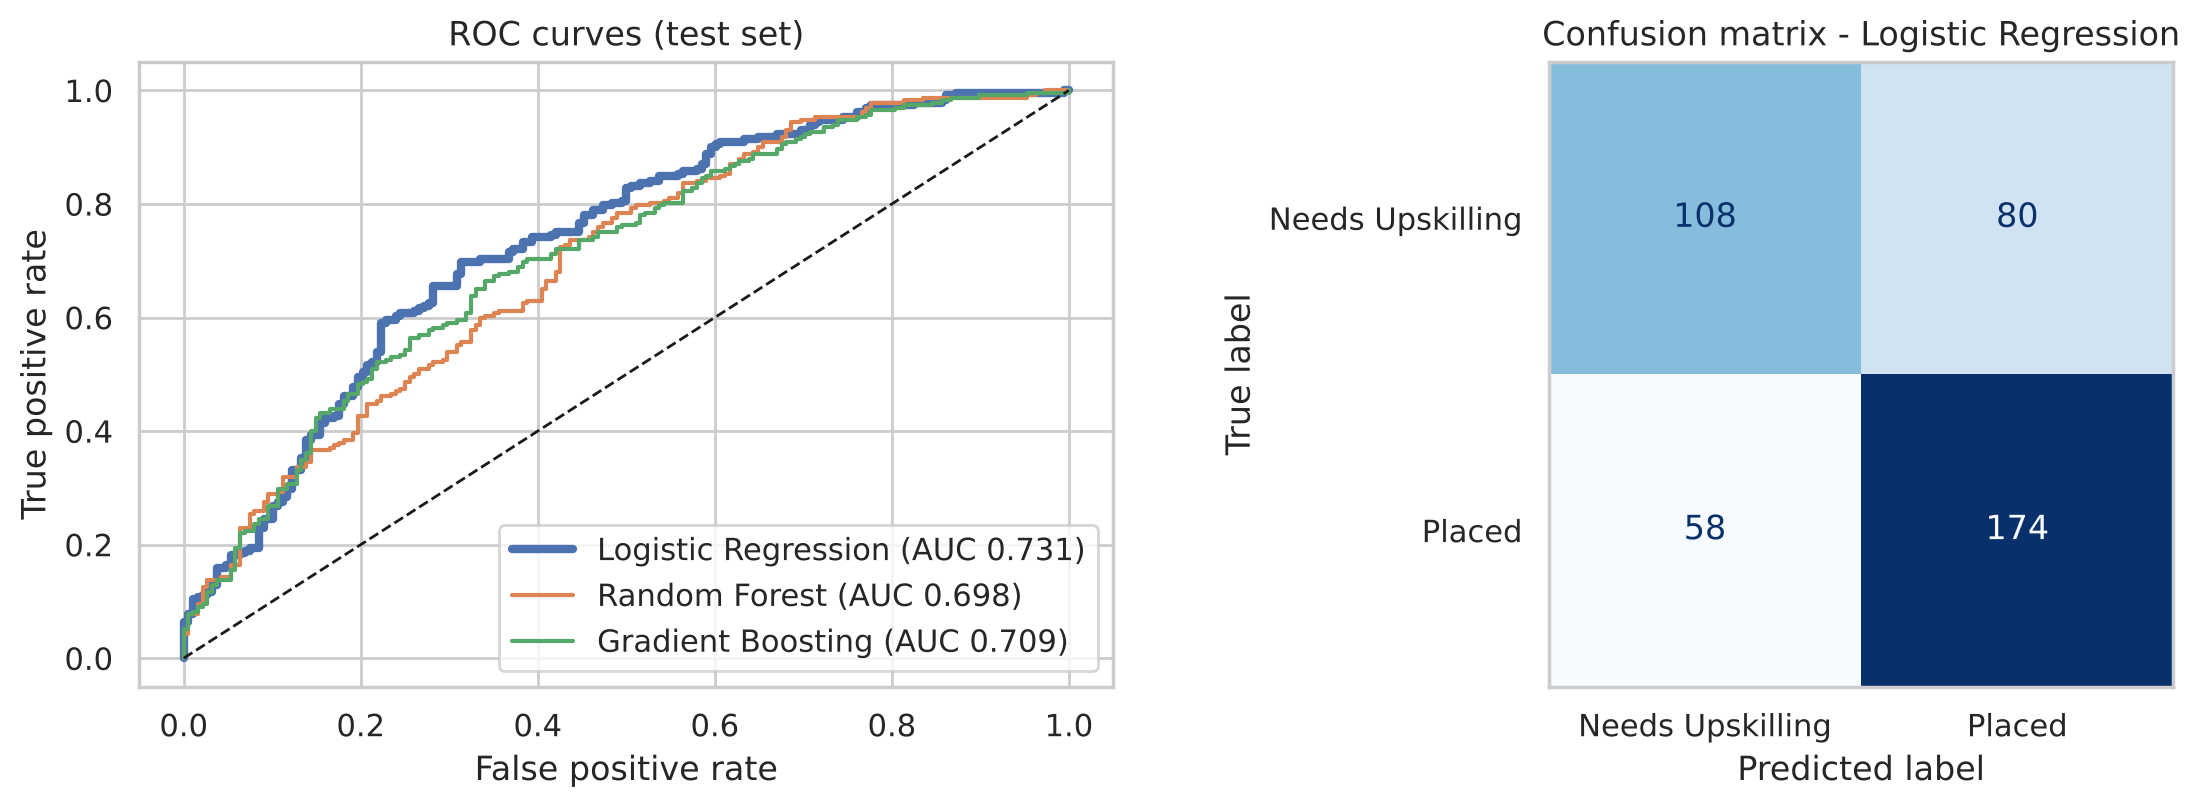

In [8]:
best_name = results["CV ROC-AUC"].idxmax()
print(f"Selected model: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})",
                 lw=3 if name == best_name else 1.5)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curves (test set)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(loc="lower right")
ConfusionMatrixDisplay.from_estimator(fitted[best_name], X_test, y_test, display_labels=["Needs Upskilling", "Placed"],
                                      cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion matrix - {best_name}"); axes[1].grid(False)
plt.tight_layout(); plt.show()

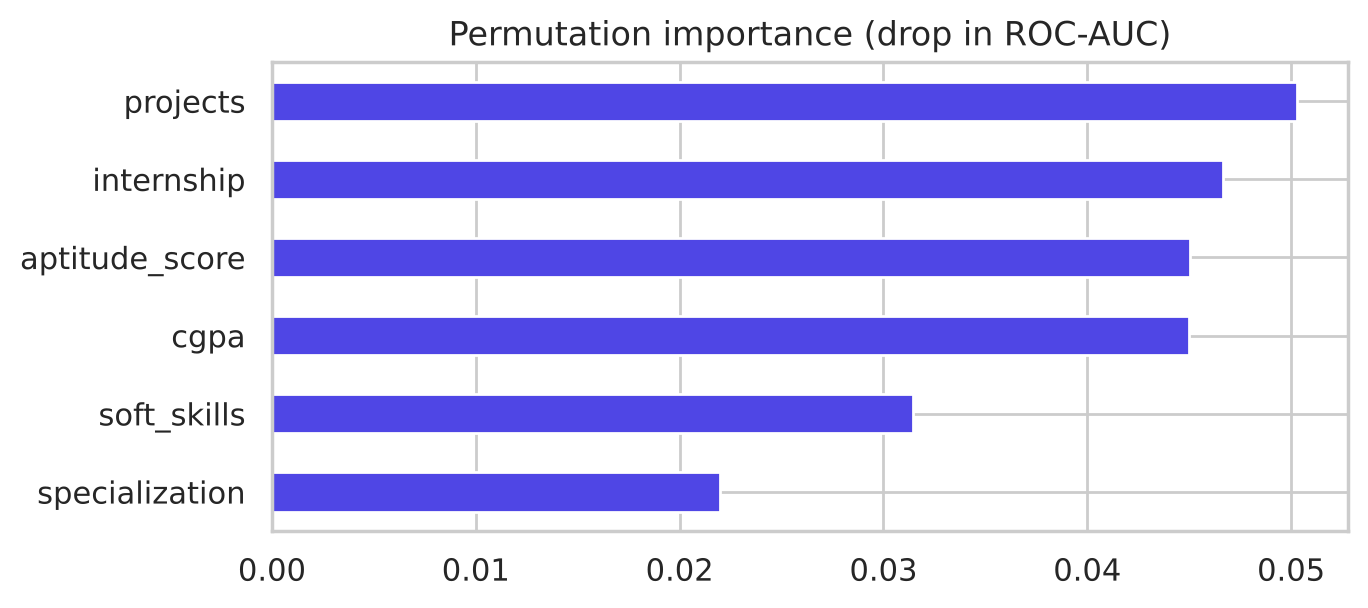

In [9]:
# Which features drive the prediction? (permutation importance on the held-out set)
imp = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc",
                             n_repeats=15, random_state=RANDOM_STATE)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp_s.plot.barh(color="#4f46e5", figsize=(7, 3.2)); plt.title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout(); plt.show()

## 8. "What-if" check (same logic the app uses for feedback)
Re-score a student after changing a single lever to see which one pushes them over the threshold.

In [10]:
student = pd.DataFrame([{"cgpa": 6.9, "aptitude_score": 55, "soft_skills": 5.5, "projects": 1,
                         "internship": 0, "specialization": "Computer Science"}])[FEATURES]
model = fitted[best_name]
base = model.predict_proba(student)[0, 1]
print(f"Baseline readiness: {base:.0%}")
for label, change in {"+1 project": {"projects": 2}, "+1 soft-skills point": {"soft_skills": 6.5},
                      "+10 aptitude points": {"aptitude_score": 65}, "complete an internship": {"internship": 1}}.items():
    p = model.predict_proba(student.assign(**change))[0, 1]
    print(f"  {label:<24} -> {p:.0%}  ({p - base:+.0%})")

Baseline readiness: 33%
  +1 project               -> 40%  (+7%)
  +1 soft-skills point     -> 39%  (+6%)
  +10 aptitude points      -> 41%  (+9%)
  complete an internship   -> 49%  (+16%)


## 9. Save the final model
The winning configuration is **refit on all cleaned data** and saved as a single bundle: the full preprocessing + model pipeline, the **exact feature order**, the decision threshold, UI ranges, and metadata.

In [11]:
final_model = clone(fitted[best_name]).fit(X, y)

def ui_range(col, step, lo_floor=0.0):
    s = df[col].dropna()
    return {"min": float(max(lo_floor, np.floor(s.min()))), "max": float(np.ceil(s.max())),
            "default": float(round(s.median(), 1)), "step": step}

bundle = {
    "pipeline": final_model,
    "features": FEATURES,                       # exact training column order
    "threshold": THRESHOLD,
    "model_name": best_name,
    "metrics": results.loc[best_name, ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].astype(float).round(4).to_dict(),
    "specializations": sorted(df["specialization"].dropna().unique().tolist()),
    "ranges": {"cgpa": ui_range("cgpa", 0.1), "aptitude_score": ui_range("aptitude_score", 1.0),
               "soft_skills": ui_range("soft_skills", 0.5, lo_floor=1.0), "projects": ui_range("projects", 1.0)},
    "data_source": DATA_SOURCE,
    "n_training_rows": int(len(df)),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, MODEL_PATH, compress=3)
print(f"Saved {MODEL_PATH.resolve()}  ({MODEL_PATH.stat().st_size / 1024:.0f} KB)")
print("Feature order:", FEATURES)

Saved /home/claude/internship-readiness-predictor/model.joblib  (2 KB)
Feature order: ['cgpa', 'aptitude_score', 'soft_skills', 'projects', 'internship', 'specialization']


In [12]:
# Sanity check: reload and score a one-row DataFrame in the saved feature order
loaded = joblib.load(MODEL_PATH)
row = pd.DataFrame([{"cgpa": 8.2, "aptitude_score": 78, "soft_skills": 7.5, "projects": 3,
                     "internship": 1, "specialization": loaded["specializations"][0]}])[loaded["features"]]
p = loaded["pipeline"].predict_proba(row)[0, 1]
print(f"{p:.0%} - {'Placement Ready' if p >= loaded['threshold'] else 'Needs Upskilling'}")

86% - Placement Ready
